# 🌳 19. Modelo original: Árbol de Combinación en el Símplex (ACS)

## 19.1 Motivación

La entrega 2 dejó tres hallazgos que apuntan a una misma idea:

1. **Ningún modelo gana en todas partes.** Random Forest tiene el menor error medio, pero por negocio empata con Ridge y Lasso (Friedman–Nemenyi, cap. 12). Su ventaja viene de los negocios **irregulares**; en los estables un modelo lineal pronostica igual de bien.
2. **El régimen del negocio se puede leer el día anterior**: volatilidad de la semana (`std7`), días sin venta, nivel, lo que vendió ayer (cap. 4b).
3. **Las reglas de combinación globales no ayudan**: un promedio o un stacking con pesos fijos no aprovecha que el mejor experto cambia según el régimen.

La propuesta es un **ensamble cuyos pesos dependen del régimen**: un árbol parte el espacio de régimen y en cada hoja combina a los expertos con pesos **convexos** (no negativos que suman 1), estimados resolviendo un problema cuadrático convexo con un solver propio. Una variable de régimen nueva es el **desacuerdo entre expertos** (desviación estándar de sus pronósticos): mide la incertidumbre del ensamble en ese punto.

In [1]:
import inspect
import pickle
import subprocess
import sys
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd().parent / "src"))
from original_model import ArbolCombinacionSimplex, EnsambleRegimen, proyectar_simplex, resolver_pesos

from comun import estilo, DATA, SEED, a_log, AZUL, NARANJA, VERDE, GRIS, PALETA
from datos import preparar, partir, X_COLS

warnings.filterwarnings("ignore")
estilo()
train, test = partir(preparar())
r = pickle.load(open(DATA / "processed" / "modelo_original.pkl", "rb"))
final = r["final"]
print("expertos:", final.nombres_, "| variables de régimen:", list(final.columnas_regimen) + ["desacuerdo"])

expertos: ['rf', 'xgb', 'ridge', 'knn', 'lag7'] | variables de régimen: ['std7', 'dias_sin_venta7', 'media7', 'lag1', 'nivel', 'festivo', 'dia_semana', 'part_efectivo', 'desacuerdo']


## 19.2 Formulación matemática

Sean $K$ expertos con pronósticos $\hat y_{ik}$ del negocio-día $i$, llevados a la escala del entrenamiento $z_{ik} = \log(1 + \hat y_{ik})$, el objetivo $y_i = \log(1 + \text{venta}_i)$ y $q$ variables de régimen $g_i \in \mathbb{R}^q$. El ACS pronostica

$$
\hat y_i \;=\; \sum_{k=1}^{K} w_{h(g_i),\,k}\; z_{ik}, \qquad w_h \in \Delta_K = \Big\{ w \in \mathbb{R}^K : w_k \ge 0,\ \textstyle\sum_k w_k = 1 \Big\}
$$ (eq-acs)

donde $h(g)$ es la hoja del árbol a la que llega $g$. Como $\sum_k w_k = 1$, el error de la combinación se escribe con los **errores de los expertos** $e_{ik} = y_i - z_{ik}$: $\;y_i - w^\top z_i = w^\top e_i$. En cada hoja $h$ con $n_h$ filas y padre con pesos $p$ y $n_{\text{padre}}$ filas, los pesos resuelven

$$
w_h = \arg\min_{w \in \Delta_K}\; f_h(w), \qquad
f_h(w) = w^\top D_h\, w + \lambda\,\frac{n_{\text{padre}}}{n_h}\,\lVert w - p \rVert_2^2, \qquad D_h = \frac{1}{n_h}\sum_{i \in h} e_i e_i^\top
$$ (eq-hoja)

El primer término es **exactamente** el error cuadrático medio de la combinación en la hoja; el segundo **encoge** los pesos hacia los del padre, más cuanto más pequeña es la hoja. En la **raíz** el encogimiento es hacia el **promedio simple** $p = \tfrac1K\mathbf 1$ con la misma $\lambda$: es la respuesta al "puzzle de la combinación de pronósticos" (Smith y Wallis, 2009), según el cual los pesos estimados suelen perder contra el promedio simple porque el error de estimarlos supera la ganancia de combinar.

**Por qué $D_h$ y no los momentos de $z$.** Escribir el ECM con $A = \tfrac1n Z^\top Z$, $b = \tfrac1n Z^\top y$ da el mismo valor dentro del símplex, pero con pronósticos en log (todos cerca de 15) $A$ tiene un autovalor enorme en la dirección de $\mathbf 1$ (≈ 1 213 contra 0,014 en nuestros datos: número de condición 86 550) y el gradiente proyectado no converge en la práctica. $D_h$ elimina esa dirección (número de condición 288). La primera versión del modelo usaba $A$ (ver 19.11). Con $\lambda' = \lambda\,n_{\text{padre}}/n_h$:

$$
\nabla f_h(w) = 2 D_h w + 2\lambda'(w - p)
$$ (eq-grad)

**Solver: gradiente proyectado** con paso $1/L$, $L = 2(\lambda_{\max}(D_h) + \lambda')$:

$$
w^{(t+1)} = \Pi_{\Delta_K}\!\Big(w^{(t)} - \tfrac{1}{L}\nabla f_h\big(w^{(t)}\big)\Big), \qquad
\Pi_{\Delta_K}(v) = \max(v - \theta, 0),\ \ \theta = \frac{\sum_{j \le \rho} u_j - 1}{\rho}
$$ (eq-pg)

donde $u$ es $v$ ordenado de mayor a menor y $\rho = \max\{j : u_j - (\sum_{r \le j} u_r - 1)/j > 0\}$ (proyección exacta al símplex de Held, Wolfe y Crowder, 1974; Duchi et al., 2008).

**Criterio de partición.** Para una variable de régimen $j$ y un umbral $u$ (uno de $B$ cuantiles), los hijos $L = \{g_j \le u\}$ y $R = \{g_j > u\}$ resuelven [](eq-hoja) y la partición elegida minimiza

$$
\mathrm{ECM}(j, u) = \frac{n_L\, \mathrm{ECM}_L(w_L) + n_R\, \mathrm{ECM}_R(w_R)}{n_L + n_R}
$$ (eq-split)

y se acepta solo si mejora el ECM del nodo en más de una fracción `ganancia_min`. Como $D$ de cada hijo se obtiene con **sumas acumuladas** de $e_i e_i^\top$ ordenadas por $g_j$, evaluar un umbral **no depende de $n$**.

**De dónde salen los $z_{ik}$ de entrenamiento.** Si el combinador se ajustara con pronósticos dentro de muestra, premiaría al experto que más memoriza (un bosque con hojas de 2 filas). Por eso los $z_{ik}$ de entrenamiento son **fuera de muestra por ajuste cruzado** (*cross-fitting*, como en el stacking de Wolpert, 1992, y el Super Learner de van der Laan et al., 2007): los días de train se parten en 4 bloques contiguos y cada bloque se pronostica con expertos entrenados con **los otros 3 bloques**. Así los expertos tienen casi tantos datos como los finales, y los pesos no castigan a los expertos que más mejoran con datos (ver 19.11). Las variables solo usan el pasado (cap. 5) y todo ocurre dentro del train de cada fold externo, así que no hay fuga hacia la validación. Para predecir, los expertos se reentrenan con todo train.

## 19.3 Pseudocódigo

```
Algoritmo ACS
Entrada : train (X, y, fecha); expertos f_1..f_K; variables de régimen g; hiperparámetros
          max_depth D, min_samples_leaf m, λ, B umbrales, ganancia_min γ, tol, max_iter
Salida  : árbol T con pesos w_h ∈ Δ_K en cada hoja; expertos reentrenados

 1  dividir los días de train en 4 bloques contiguos
 2  para cada bloque b:                                                 # ajuste cruzado
 3      entrenar f_1..f_K con los otros bloques;  Z_b ← log(1 + f_k(X_b)),  G_b ← [g(X_b), sd_k(Z_b)]
 4  Z, y, G ← unir los bloques;  y ← log(1 + y);  E ← y·1ᵀ − Z          # errores de los expertos
 5  w_raíz ← PG(D = EᵀE/n, p = (1/K)·1, λ' = λ)                        # ec. (eq-pg), encoge al promedio
 6  CRECER(todas las filas, w_raíz, profundidad 0)
 7  reentrenar f_1..f_K con todo train;  devolver T

 CRECER(I, w, d):
 8  si d = D  o  |I| < 2m:  hoja con pesos w;  terminar
 9  para cada variable j y umbral u ∈ cuantiles de G[I, j]:
10      con sumas acumuladas de e eᵀ: D_L, D_R
11      si n_L ≥ m y n_R ≥ m:  w_L ← PG(D_L, w, λ n/n_L);  w_R ← PG(D_R, w, λ n/n_R)
12      ECM(j, u) ← ec. (eq-split)
13  si ECM(nodo) − min ECM(j, u) ≤ γ·ECM(nodo):  hoja con pesos w;  terminar
14  CRECER(I_L, w_L, d + 1);  CRECER(I_R, w_R, d + 1)

 PG(D, p, λ'):                                                         # gradiente proyectado
15  L ← 2(λ_max(D) + λ');  w ← p
16  repetir hasta ‖w_nuevo − w‖_∞ < tol  o  max_iter (5 000):  w ← Π_Δ(w − ∇f(w)/L)

 Predicción de una fila x:  bajar por T según g(x) hasta la hoja h;  ŷ = expm1(Σ_k w_h,k · log(1 + f_k(x)))
```

## 19.4 Propiedades demostradas

**Proposición 1 (convexidad y unicidad).** $f_h$ es convexa; si $\lambda' > 0$ es $\mu$-fuertemente convexa con $\mu = 2\lambda'$, y [](eq-hoja) tiene un único minimizador.

*Demostración.* $D_h = \frac{1}{n_h}\sum e_i e_i^\top$ es semidefinida positiva, así que $w^\top D_h w$ es convexa, y $\lambda'\lVert w - p\rVert^2$ tiene hessiano $2\lambda' I$. El hessiano de $f_h$ es $2D_h + 2\lambda' I \succeq 2\lambda' I$. $\Delta_K$ es convexo, cerrado y acotado (compacto), así que existe un mínimo (Weierstrass), y la convexidad fuerte lo hace único. $\blacksquare$

**Proposición 2 (convergencia del solver).** Con paso $1/L$, el gradiente proyectado [](eq-pg) cumple
$f_h(w^{(t)}) - f_h^\star \le \dfrac{L\, \lVert w^{(0)} - w^\star\rVert^2}{2t} \le \dfrac{L}{t}$, y si $\lambda' > 0$, $\lVert w^{(t)} - w^\star \rVert^2 \le (1 - \mu/L)^t \lVert w^{(0)} - w^\star\rVert^2$ (convergencia lineal).

*Demostración.* $\nabla f_h$ es Lipschitz con constante $L = 2(\lambda_{\max}(D_h) + \lambda')$, el mayor autovalor del hessiano. Para una función convexa $L$-suave y un conjunto convexo cerrado, el gradiente proyectado con paso $1/L$ satisface el lema de descenso $f(w^{(t+1)}) \le f(w) + \nabla f(w)^\top(w^{(t+1)} - w) + \tfrac{L}{2}\lVert w^{(t+1)}-w\rVert^2$ y la desigualdad de la proyección $\langle w^{(t)} - \tfrac1L\nabla f - w^{(t+1)}, w^\star - w^{(t+1)}\rangle \le 0$; sumando ambas desde $t = 0$ y telescopando se obtiene la cota $O(1/t)$ (Beck, 2017, Teorema 10.21). Con convexidad fuerte, el mapa de gradiente es una contracción con factor $1 - \mu/L$ (Beck, 2017, Teorema 10.29). La segunda desigualdad usa que el diámetro de $\Delta_K$ es $\sqrt 2$: $\lVert w^{(0)} - w^\star\rVert^2 \le 2$. $\blacksquare$

*Consecuencia práctica:* la tasa lineal $(1-\mu/L)$ depende del número de condición $L/\mu$. Con la matriz de errores $D_h$ (condición ≈ 288 en estos datos) el solver converge en cientos de iteraciones; con los momentos sin centrar de la primera versión (condición ≈ 86 550) no convergía en 500 (19.11). La prueba unitaria `test_solver_cumple_kkt_con_expertos_correlacionados` verifica las condiciones de optimalidad en ese caso.

**Proposición 3 (terminación del árbol).** El algoritmo termina con a lo sumo $\min(2^{D+1} - 1,\; 2n/m)$ nodos.

*Demostración.* Cada partición produce dos hijos con al menos $m$ filas y la profundidad está acotada por $D$, así que el árbol es binario de profundidad $\le D$ ($\le 2^{D+1}-1$ nodos) y sus hojas son disjuntas con $\ge m$ filas ($\le n/m$ hojas, $\le 2n/m$ nodos). Cada nodo evalúa a lo sumo $qB$ candidatos y cada solver para en a lo sumo `max_iter` iteraciones. $\blacksquare$

**Proposición 4 (casi nunca peor que el mejor experto en entrenamiento).** Sea $\mathrm{ECM}(T)$ el error cuadrático medio del árbol sobre sus datos de ajuste. Entonces $\mathrm{ECM}(T) \le \min_k \mathrm{ECM}(e_k) + \lambda(1 - 1/K)$, donde $e_k$ es "usar solo el experto $k$". Con $\lambda \to 0$ el árbol nunca es peor que el mejor experto; con $\lambda > 0$ se cede a lo sumo $\lambda(1-1/K)$ de ajuste a cambio de estabilidad.

*Demostración.* (i) En la raíz, cada vértice $e_k \in \Delta_K$ es factible, así que $\mathrm{ECM}(w_{\text{raíz}}) \le f(w_{\text{raíz}}) \le f(e_k) = \mathrm{ECM}(e_k) + \lambda\lVert e_k - \tfrac1K\mathbf 1\rVert^2$, y $\lVert e_k - \tfrac1K \mathbf 1\rVert^2 = 1 - 1/K$. (ii) En un hijo $h$ con padre de pesos $p$: $p$ es factible y su penalización es 0, así que $\mathrm{ECM}_h(w_h) \le f_h(w_h) \le f_h(p) = \mathrm{ECM}_h(p)$. Promediando sobre los dos hijos, $\mathrm{ECM}(\text{hijos}) \le \mathrm{ECM}(\text{padre})$: ninguna partición empeora el ajuste, y por inducción el árbol no supera el ECM de la raíz. $\blacksquare$

La Proposición 4 es una garantía **de entrenamiento**: no asegura que el ACS gane fuera de muestra, como se verá en el capítulo 20.

**Proposición 5 (complejidad).** Con $n$ filas, $K$ expertos, $q$ variables de régimen, $B$ umbrales, profundidad $D$ e $I$ iteraciones del solver:

- *Entrenamiento del árbol:* $O\big(D\, q\, (n \log n + n K^2) + N_{\text{nodos}}\, q\, B\, (K^3 + I K^2)\big)$. En cada nivel las filas se reparten entre los nodos: ordenar cuesta $O(n \log n)$ y las sumas acumuladas de $e_i e_i^\top$ $O(nK^2)$ por variable; cada candidato resuelve dos problemas de tamaño $K$ ($K^3$ por el autovalor, $IK^2$ por las iteraciones), **sin depender de $n$**.
- *Inferencia:* $O(D + K)$ por fila para el árbol, más el costo de los $K$ expertos.
- *Memoria:* $O(nK^2)$ para las sumas acumuladas de un nodo.
- *Total del ensamble:* $(n_{\text{bloques}} + 1)\times$ el costo de entrenar los expertos, más el árbol.

### Verificación empírica de la complejidad

Se mide el tiempo de ajuste de **un nivel** del árbol (la raíz evalúa todos los candidatos) variando por separado $n$ (replicando los pronósticos fuera de muestra con un pequeño ruido), $q$ y $B$, con 3 repeticiones (mediana). Con un solo nivel y pocos umbrales domina el término $q(n\log n + nK^2)$, así que el exponente en $n$ debe estar cerca de 1; con $n$ fijo, el costo de los candidatos crece lineal en $q$ y en $B$ y **no depende de $n$**.

segundos por n: {8000: 0.067, 16000: 0.087, 32000: 0.118, 64000: 0.198, 128000: 0.407, 256000: 0.799}


,exponente empírico,teórico
n (todo el rango),0.72,≈ 1 (n log n + n K²)
n (128 mil → 256 mil),0.97,≈ 1
q,0.84,1
B,1.01,1


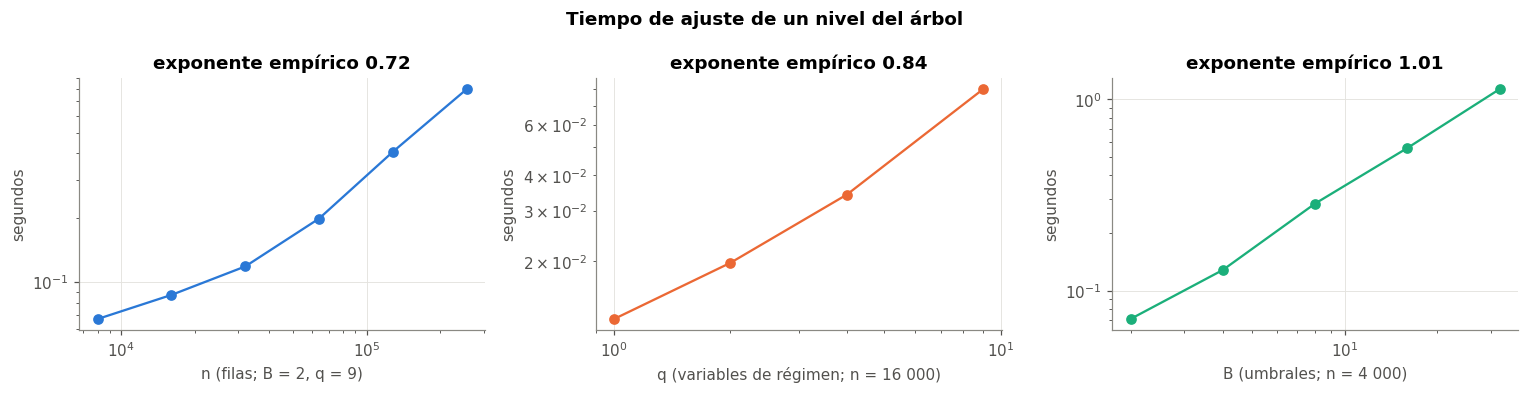

In [2]:
Z, y_oof, G = final.oof_
K = Z.shape[1]
rng = np.random.default_rng(SEED)
f4 = lambda df: df.applymap(lambda v: f"{v:.4f}" if isinstance(v, (float, np.floating)) else v)  # 4 decimales


def tiempo_fit(n, q, B, reps=3):
    # un solo nivel (la raíz evalúa todos los candidatos): aísla los términos n log n + n K^2 y q B (K^3 + I K^2)
    idx = rng.integers(0, len(y_oof), n)
    X = np.column_stack([Z[idx] + rng.normal(0, 0.01, (n, K)), G[idx][:, :q] + rng.normal(0, 0.01, (n, q))])
    ts = []
    for _ in range(reps):
        t = time.perf_counter()
        ArbolCombinacionSimplex(n_expertos=K, max_depth=1, min_samples_leaf=20, lam=0.1, n_umbrales=B).fit(X, y_oof[idx])
        ts.append(time.perf_counter() - t)
    return float(np.median(ts))


tam = [8000, 16000, 32000, 64000, 128000, 256000]
t_n = [tiempo_fit(n, 9, 2) for n in tam]
qs = [1, 2, 4, 9]
t_q = [tiempo_fit(16000, q, 2) for q in qs]
Bs = [2, 4, 8, 16, 32]
t_B = [tiempo_fit(4000, 9, B) for B in Bs]
b_n, b_q, b_B = (np.polyfit(np.log(x), np.log(t), 1)[0] for x, t in [(tam, t_n), (qs, t_q), (Bs, t_B)])
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
for a_, x, t, b, et, col in [(ax[0], tam, t_n, b_n, "n (filas; B = 2, q = 9)", AZUL), (ax[1], qs, t_q, b_q, "q (variables de régimen; n = 16 000)", NARANJA),
                             (ax[2], Bs, t_B, b_B, "B (umbrales; n = 4 000)", VERDE)]:
    a_.loglog(x, t, "o-", color=col); a_.set_xlabel(et); a_.set_ylabel("segundos"); a_.set_title(f"exponente empírico {b:.2f}")
plt.suptitle("Tiempo de ajuste de un nivel del árbol", fontweight="bold")
plt.tight_layout()
b_final = np.log(t_n[-1] / t_n[-2]) / np.log(tam[-1] / tam[-2])
print("segundos por n:", dict(zip(tam, np.round(t_n, 3))))
pd.DataFrame({"exponente empírico": [b_n, b_final, b_q, b_B],
              "teórico": ["≈ 1 (n log n + n K²)", "≈ 1", "1", "1"]},
             index=["n (todo el rango)", "n (128 mil → 256 mil)", "q", "B"]).round(2)

**Lectura.**

- **En $q$ y en $B$ los exponentes son 0,84 y 1,01**, cerca de 1, como predice la Proposición 5: evaluar candidatos cuesta lineal en el número de variables y de umbrales.
- **En $n$ el exponente sobre todo el rango es 0,72**, porque hasta ~32 mil filas domina el **costo fijo** de resolver los problemas de hoja, que no depende de $n$ (la ventaja de las sumas acumuladas).
- **En el tramo final (128 mil → 256 mil filas) el exponente es 0,97**: ahí domina el término $n\log n + nK^2$ y el comportamiento es lineal, como dice la teoría.
- Ajustar el árbol es barato (0,8 s con 256 mil filas); el costo del ACS completo lo dominan los expertos, que se entrenan 5 veces (4 bloques y el final).

## 19.5 Implementación

La clase `ArbolCombinacionSimplex` (en `src/original_model.py`) hereda de `BaseEstimator` y `RegressorMixin`, así que funciona con `clone`, `Pipeline` y `cross_val_score`. Solo usa numpy para los cálculos; scikit-learn aporta la interfaz y las validaciones de entrada. Las piezas centrales:

In [3]:
print(inspect.getsource(proyectar_simplex))
print(inspect.getsource(resolver_pesos))

def proyectar_simplex(v):
    """Proyección euclidiana de v sobre el símplex {w : w >= 0, sum(w) = 1}.

    Algoritmo exacto por ordenamiento (Held et al., 1974; Duchi et al., 2008), O(K log K).

    Parameters
    ----------
    v : numpy.ndarray, forma (K,)

    Returns
    -------
    numpy.ndarray
        El punto del símplex más cercano a ``v``.
    """
    u = np.sort(v)[::-1]
    acum = np.cumsum(u) - 1.0
    k = np.arange(1, len(v) + 1)
    rho = np.nonzero(u - acum / k > 0)[0][-1]
    theta = acum[rho] / (rho + 1.0)
    return np.maximum(v - theta, 0.0)

def resolver_pesos(A, b, previo, lam, max_iter=5000, tol=1e-9):
    """Pesos óptimos en el símplex para una hoja, por gradiente proyectado.

    Minimiza  f(w) = w'Aw - 2b'w + lam * ||w - previo||^2   sujeto a  w >= 0, sum(w) = 1.
    En el ACS, A = E'E/n es la matriz de segundos momentos de los errores de los expertos y b = 0
    (ver ``_momentos``), así que f es el error cuadrático medio de la combinación más la penalización

In [4]:
print(inspect.getsource(ArbolCombinacionSimplex._mejor_particion))

    def _mejor_particion(self, idx, Z, G, y, w_padre):
        """Busca (variable, umbral) que minimiza el ECM ponderado de los dos hijos.

        Usa sumas acumuladas de los productos de errores e e' ordenadas por la variable: evaluar un
        umbral cuesta O(K^3 + I K^2) y no depende de n.
        """
        n, m = len(idx), self.min_samples_leaf
        # errores de los expertos en el nodo y sus productos por fila: e e' (ver _momentos)
        En = y[idx][:, None] - Z[idx]
        ee = np.einsum("ij,ik->ijk", En, En)
        mejor = None
        for j in range(G.shape[1]):
            g = G[idx, j]
            orden = np.argsort(g, kind="mergesort")
            gs = g[orden]
            c_ee = np.cumsum(ee[orden], 0)
            tot_ee = c_ee[-1]
            K = Z.shape[1]
            umbrales = np.unique(np.quantile(gs, np.linspace(0, 1, self.n_umbrales + 2)[1:-1]))
            for u in umbrales:
                k = np.searchsorted(gs, u, side="right")  # filas con g <= u
     

## 19.6 Pruebas unitarias

`tests/test_original_model.py` (pytest) verifica: (i) que el modelo **aprende** en un conjunto sintético con solución conocida (dos regímenes, cada uno con un experto bueno: el árbol debe partir en $g = 0$ y dar peso $> 0{,}95$ al experto correcto de cada lado); (ii) la **reproducibilidad** con la misma semilla; (iii) el **manejo de entradas inválidas** (parámetros fuera de rango, nulos, dimensiones incorrectas, predecir sin entrenar); (iv) la **compatibilidad** con `clone`, `get_params` y `cross_val_score`; y además que el solver coincide con una búsqueda exhaustiva y que se cumple la Proposición 4.

In [5]:
salida = subprocess.run([sys.executable, "-m", "pytest", "../tests", "-v", "--no-header", "-p", "no:cacheprovider"],
                        capture_output=True, text=True, cwd=Path.cwd())
print("\n".join(l for l in salida.stdout.splitlines() if "PASSED" in l or "FAILED" in l or "passed" in l or "failed" in l))

../tests/test_original_model.py::test_proyeccion_queda_en_el_simplex PASSED [  6%]
../tests/test_original_model.py::test_proyeccion_de_un_punto_del_simplex_es_el_mismo_punto PASSED [ 12%]
../tests/test_original_model.py::test_solver_coincide_con_busqueda_exhaustiva PASSED [ 18%]
../tests/test_original_model.py::test_solver_cumple_kkt_con_expertos_correlacionados PASSED [ 25%]
../tests/test_original_model.py::test_aprende_los_dos_regimenes PASSED   [ 31%]
../tests/test_original_model.py::test_no_es_peor_que_el_mejor_experto_en_entrenamiento PASSED [ 37%]
../tests/test_original_model.py::test_profundidad_cero_da_pesos_globales PASSED [ 43%]
../tests/test_original_model.py::test_misma_semilla_mismo_resultado PASSED [ 50%]
../tests/test_original_model.py::test_parametros_invalidos[params0] PASSED [ 56%]
../tests/test_original_model.py::test_parametros_invalidos[params1] PASSED [ 62%]
../tests/test_original_model.py::test_parametros_invalidos[params2] PASSED [ 68%]
../tests/test_original_mo

## 19.7 Hiperparámetros dentro de la validación anidada

El ACS pasa por **el mismo protocolo** que los 28 benchmarks: los mismos 4 folds externos, la misma semilla y el mismo presupuesto de **16 evaluaciones** con optimización bayesiana (TPE). En cada fold externo:

1. Los expertos usan los hiperparámetros elegidos **en el bucle interno de ese fold** en la entrega 2 (para Random Forest, XGBoost, Ridge y KNN, su mejor optimizador).
2. Se generan los pronósticos fuera de muestra (4 bloques, ajuste cruzado) dentro del train del fold.
3. **Bucle interno del ACS:** esos pronósticos se parten en el tiempo (los primeros 3/4 de los días para ajustar el árbol, el último 1/4 para medir) y el TPE busca `max_depth` ∈ [0, 4], `min_samples_leaf` ∈ [100, 2000] (log) y $\lambda$ ∈ [0,01; 10] (log).
4. Con los mejores hiperparámetros se reajusta el árbol y se predice la semana de validación externa.

In [6]:
hp = pd.DataFrame([{"fold externo": f["fold"] + 1, **f["params_arbol"], "hojas": f["n_hojas"], "segundos": f["seg_fit"]}
                   for f in r["folds"]])
hp.loc["final"] = ["todo train", *r["params_final"].values(), final.arbol_.n_hojas(), r["seg_fit_final"]]
f4(hp)

,fold externo,max_depth,min_samples_leaf,lam,hojas,segundos
0,1,4,267,0.0151,11,60.4076
1,2,3,248,2.5722,6,29.1712
2,3,4,188,0.0351,14,80.1296
3,4,3,819,0.1407,6,36.1091
final,todo train,2,318,0.0136,4,71.8749


### El árbol final

Así quedó el árbol ajustado con todo train (el que usa el tablero). Los nombres de los nodos son los del ajuste final:

In [7]:
nombres_g = list(final.columnas_regimen) + ["desacuerdo"]
def describir(i=0, pref=""):
    n = final.arbol_.nodos_[i]
    pesos = ", ".join(f"{e} {w:.2f}" for e, w in zip(final.nombres_, n["pesos"]))
    if "var" in n:
        print(f"{pref}nodo {i}: n = {n['n']:,}, ECM = {n['ecm']:.3f}  →  ¿{nombres_g[n['var']]} ≤ {n['umbral']:.3f}?")
        describir(n["izq"], pref + "   sí: "); describir(n["der"], pref + "   no: ")
    else:
        print(f"{pref}HOJA {i}: n = {n['n']:,}, ECM = {n['ecm']:.3f}, pesos [{pesos}]")
describir()

nodo 0: n = 22,205, ECM = 0.630  →  ¿part_efectivo ≤ 0.616?
   sí: nodo 1: n = 11,756, ECM = 0.326  →  ¿dia_semana ≤ 4.000?
   sí:    sí: HOJA 2: n = 8,463, ECM = 0.372, pesos [rf 0.47, xgb 0.04, ridge 0.00, knn 0.37, lag7 0.11]
   sí:    no: HOJA 3: n = 3,293, ECM = 0.182, pesos [rf 0.05, xgb 0.30, ridge 0.00, knn 0.28, lag7 0.37]
   no: nodo 4: n = 10,449, ECM = 0.959  →  ¿nivel ≤ 11.437?
   no:    sí: HOJA 5: n = 615, ECM = 2.989, pesos [rf 0.49, xgb 0.14, ridge 0.22, knn 0.14, lag7 0.00]
   no:    no: HOJA 6: n = 9,834, ECM = 0.824, pesos [rf 0.24, xgb 0.62, ridge 0.00, knn 0.15, lag7 0.00]


**Interpretación.** El árbol final tiene 4 hojas y sus cortes son legibles:

1. **Primer corte: el tipo de negocio** (`part_efectivo` ≤ 0,62). Los negocios que venden mucho en efectivo (KCO y tiendas, cap. 4b) quedan a un lado y los que venden con datáfono y crédito (EDS) al otro.
2. **Negocios de efectivo, de lunes a viernes:** Random Forest (0,47) y KNN (0,37).
3. **Negocios de efectivo, sábado y domingo:** el **ingenuo estacional** pesa 0,37 y XGBoost 0,30. El fin de semana se parece más al mismo día de la semana anterior que a la media reciente.
4. **Negocios grandes con datáfono y crédito (EDS):** **XGBoost** (0,62) y Random Forest (0,24).
5. **Negocios muy pequeños** (`nivel` ≤ 11,4, unos 90 mil COP por día): Random Forest (0,49) y Ridge (0,22). Es la hoja con más error (ECM 3,0).

Ninguna hoja usa a Ridge salvo la de negocios muy pequeños, y la variable de desacuerdo no aparece en el árbol final.

## 19.8 Ablación y reglas estándar de combinación

Se retira **un componente a la vez** y se reajusta con los mismos hiperparámetros y los mismos pronósticos fuera de muestra, en los 4 folds externos. Se compara además con las **reglas estándar** que pide la guía (promedio simple, pesos por error global, pesos globales en el símplex y stacking lineal sin restricciones).

,RMSE log media,Δ RMSE log vs ACS,MAE log media,Δ MAE log vs ACS
modelo,,,,
sin knn,0.8970,-0.0011,0.2913,0.0035
sin lag7,0.8974,-0.0008,0.2844,-0.0034
ACS completo,0.8981,0.0000,0.2878,0.0000
pesos globales en el símplex,0.8989,0.0008,0.2863,-0.0015
sin desacuerdo,0.8994,0.0013,0.2877,-0.0001
sin encogimiento (lam = 0),0.9002,0.0021,0.2871,-0.0008
sin rf,0.9003,0.0022,0.2894,0.0015
stacking lineal,0.9004,0.0023,0.2901,0.0023
sin ridge,0.9009,0.0028,0.2889,0.0011


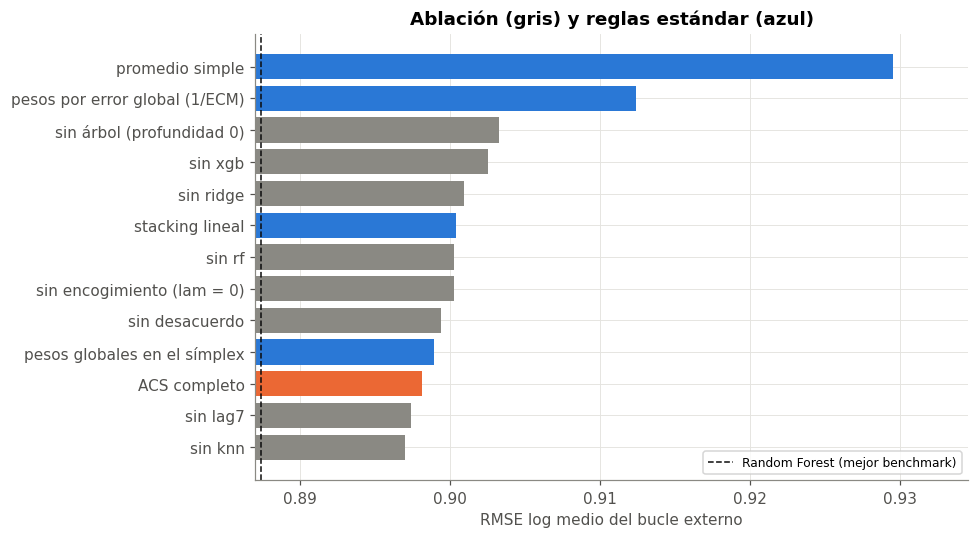

In [8]:
abl = pd.read_csv("resultados/original_ablacion.csv", index_col=0)
res = pd.read_csv("resultados/original_resumen.csv", index_col=0)
abl.loc["ACS completo"] = res.loc["ACS (original)", abl.columns]
abl = abl.drop(index=[i for i in abl.index if i.startswith("experto")])
abl["Δ RMSE log vs ACS"] = abl["RMSE log media"] - abl.loc["ACS completo", "RMSE log media"]
abl["Δ MAE log vs ACS"] = abl["MAE log media"] - abl.loc["ACS completo", "MAE log media"]
fig, ax = plt.subplots(figsize=(9, 5))
s = abl["RMSE log media"].sort_values()
colores = [NARANJA if i == "ACS completo" else GRIS if i.startswith("sin") else AZUL for i in s.index]
ax.barh(s.index, s.values, color=colores)
ax.axvline(res.loc["Random Forest · Grid", "RMSE log media"], color="#0b0b0b", ls="--", lw=1, label="Random Forest (mejor benchmark)")
ax.set_xlim(s.min() - 0.01, s.max() + 0.005); ax.set_xlabel("RMSE log medio del bucle externo"); ax.legend(fontsize=8)
ax.set_title("Ablación (gris) y reglas estándar (azul)")
plt.tight_layout()
f4(abl[["RMSE log media", "Δ RMSE log vs ACS", "MAE log media", "Δ MAE log vs ACS"]].sort_values("RMSE log media"))

**Lectura de la ablación (v4).**

- **Los componentes aportan poco y no todos en la misma dirección.**
  - Retirar XGBoost (+0,0044), Ridge (+0,0028), Random Forest (+0,0022), el encogimiento (+0,0021) o el desacuerdo (+0,0013) empeora el RMSE log.
  - Retirar KNN (−0,0011) o el ingenuo estacional (−0,0008) lo **mejora** levemente.
  - Sin el árbol, con pesos globales y λ buscada, el RMSE log sube 0,005.
  - Todas las diferencias son del orden de milésimas, comparables con el ruido entre folds (desviación ≈ 0,13).
- **El ACS supera a las cuatro reglas estándar**, pero a una apenas: pesos globales en el símplex 0,8989 (+0,0008), stacking lineal 0,9004 (+0,0023), pesos por error global 0,9124 (+0,0143) y promedio simple 0,9295 (+0,0314). La partición por régimen agrega **muy poco** sobre los pesos globales bien estimados. Es otra cara del puzzle de la combinación.
- **En MAE log** varios componentes empeoran el resultado: sin ellos el MAE baja hasta 0,0034. No hay una estructura que mejore uniformemente las dos métricas.

## 19.9 Sensibilidad, estabilidad y robustez

**Sensibilidad a los hiperparámetros propios.** Con los pronósticos fuera de muestra del modelo final, se ajusta el árbol en los primeros 3/4 de los días y se mide en el último 1/4, para una rejilla de profundidad × $\lambda$.

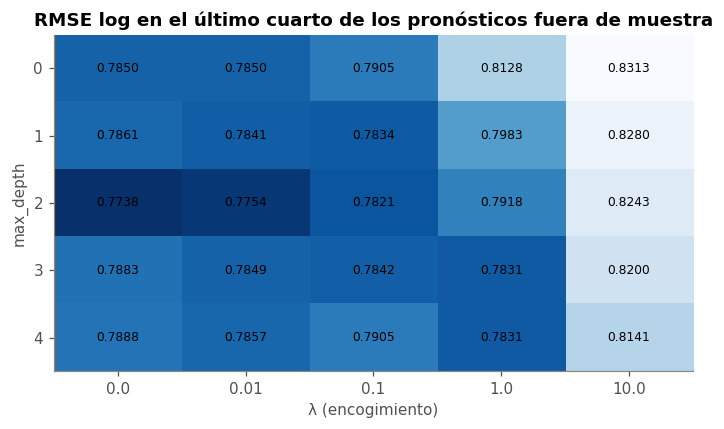

In [9]:
XZ = np.column_stack([Z, G])
corte = int(len(y_oof) * 0.75)
prof, lams = [0, 1, 2, 3, 4], [0.0, 0.01, 0.1, 1.0, 10.0]
sens = pd.DataFrame(index=prof, columns=lams, dtype=float)
for d in prof:
    for l in lams:
        a = ArbolCombinacionSimplex(n_expertos=K, max_depth=d, lam=l, min_samples_leaf=r['params_final']['min_samples_leaf']).fit(XZ[:corte], y_oof[:corte])
        sens.loc[d, l] = np.sqrt(np.mean((a.predict(XZ[corte:]) - y_oof[corte:]) ** 2))
sens.index.name, sens.columns.name = "max_depth", "λ"
fig, ax = plt.subplots(figsize=(6.5, 4))
im = ax.imshow(sens.values.astype(float), cmap="Blues_r", aspect="auto")
ax.set_xticks(range(len(lams))); ax.set_xticklabels(lams); ax.set_yticks(range(len(prof))); ax.set_yticklabels(prof)
for i in range(len(prof)):
    for j in range(len(lams)):
        ax.text(j, i, f"{sens.iloc[i, j]:.4f}", ha="center", va="center", fontsize=8)
ax.set_xlabel("λ (encogimiento)"); ax.set_ylabel("max_depth"); ax.grid(False)
ax.set_title("RMSE log en el último cuarto de los pronósticos fuera de muestra")
plt.tight_layout()

**Lectura.**

- **El mejor punto es profundidad 2 con λ chica:** 0,774, contra 0,785 sin árbol.
- **Más profundidad empeora:** con 3 y 4 niveles el error sube a 0,783–0,789. El árbol empieza a sobreajustar con muy pocas particiones.
- **Un λ grande (≥ 1) empeora mucho** (hasta 0,83): encoge las hojas hacia el promedio simple y pierde la adaptación por régimen.
- La búsqueda bayesiana eligió justamente profundidad 2 y λ = 0,014.
- **Advertencia:** este mapa mide el error **dentro** de los pronósticos fuera de muestra (su último cuarto). La mejora interna de 0,011 sobre los pesos globales **no se trasladó** a la validación externa (cap. 20): es el patrón de sobreajuste del combinador que se discute en 19.11.

**Estabilidad ante semillas.** El árbol es determinista; el azar está en los expertos (Random Forest y XGBoost). Se reentrena el ACS final con 3 semillas distintas para los expertos y se mide en test.

In [10]:
sys.path.insert(0, ".")
from modelo_original import ensamble, buscar_arbol, EXPERTOS
from experimentos import cargar
from modelos import crear_modelo
filas = []
params = {m: cargar("reg", m, "ninguno", o)["params_final"] for m, o in EXPERTOS.items()}
for s in [42, 7, 2026]:
    e = ensamble(params)
    e.expertos = [(m, crear_modelo("reg", m, params[m], semilla=s)) for m in EXPERTOS]
    e.fit(train, train["venta_total"].to_numpy())
    e.reajustar_arbol(**r["params_final"])
    p = e.predict(test)
    rf = e.modelos_[0].predict(test[X_COLS])
    filas.append({"semilla de los expertos": s, "RMSE log ACS (test)": np.sqrt(np.mean((a_log(test["venta_total"]) - a_log(p)) ** 2)),
                  "RMSE log Random Forest (test)": np.sqrt(np.mean((a_log(test["venta_total"]) - a_log(rf)) ** 2)),
                  "MAE log ACS (test)": np.mean(np.abs(a_log(test["venta_total"]) - a_log(p))),
                  "MAE log Random Forest (test)": np.mean(np.abs(a_log(test["venta_total"]) - a_log(rf)))})
sem = pd.DataFrame(filas).set_index("semilla de los expertos")
sem.loc["desv. estándar"] = sem.std()
f4(sem)

,RMSE log ACS (test),RMSE log Random Forest (test),MAE log ACS (test),MAE log Random Forest (test)
semilla de los expertos,,,,
42,0.6108,0.6221,0.2111,0.2164
7,0.6116,0.6198,0.2118,0.2170
2026,0.6092,0.6218,0.2097,0.2156
desv. estándar,0.0012,0.0013,0.0010,0.0007


**Lectura.** La variación por semilla de los expertos es pequeña (±0,001 en RMSE log). **En las tres semillas el ACS es mejor que Random Forest en test**, tanto en RMSE log (0,609–0,612 contra 0,620–0,622) como en MAE log (0,210–0,212 contra 0,216–0,217). Es una ventaja estable en test, aunque en la validación externa el ACS queda por debajo de Random Forest. Que los dos periodos no coincidan es otra señal de que la diferencia entre los dos modelos está en el nivel del ruido.

**Robustez ante un experto con ruido.** Si un experto se degrada, el ACS debería bajar su peso. Se agrega ruido gaussiano creciente a los pronósticos de Random Forest (fuera de muestra y en la evaluación) y se compara el ACS con el promedio simple.

In [11]:
filas = []
for sd in [0.0, 0.25, 0.5, 1.0, 2.0]:
    Zr = Z.copy(); Zr[:, 0] += rng.normal(0, sd, len(Zr))
    XZr = np.column_stack([Zr, G])
    a = ArbolCombinacionSimplex(n_expertos=K, **r["params_final"]).fit(XZr[:corte], y_oof[:corte])
    filas.append({"ruido en RF (desv., log)": sd, "peso medio de RF": a.pesos(XZr[corte:])[:, 0].mean(),
                  "RMSE log ACS": np.sqrt(np.mean((a.predict(XZr[corte:]) - y_oof[corte:]) ** 2)),
                  "RMSE log promedio simple": np.sqrt(np.mean((Zr[corte:].mean(1) - y_oof[corte:]) ** 2))})
f4(pd.DataFrame(filas))

,"ruido en RF (desv., log)",peso medio de RF,RMSE log ACS,RMSE log promedio simple
0,0.0000,0.2585,0.7753,0.8349
1,0.2500,0.0166,0.7856,0.8372
2,0.5000,0.0119,0.7906,0.8398
3,1.0000,0.0141,0.7868,0.8607
4,2.0000,0.0016,0.7854,0.9194


**Lectura: el ACS es robusto ante un experto degradado.**

- Con apenas 0,25 de ruido en Random Forest, su peso medio cae de 0,26 a 0,02: el ACS **deja de usarlo**.
- Su error casi no cambia (0,775 a 0,79).
- El promedio simple, en cambio, se degrada de 0,835 a 0,92.

Es la ventaja práctica de aprender los pesos en lugar de fijarlos.

**Menor tamaño de muestra.** Se reduce la fracción de negocios con que se ajusta el árbol (manteniendo la evaluación) para ver cuánto depende de la cantidad de datos.

In [12]:
filas = []
for frac in [1.0, 0.5, 0.25, 0.1]:
    sel = rng.random(corte) < frac
    a = ArbolCombinacionSimplex(n_expertos=K, **{**r["params_final"], "min_samples_leaf": max(30, int(r["params_final"]["min_samples_leaf"] * frac))}).fit(XZ[:corte][sel], y_oof[:corte][sel])
    filas.append({"fracción de filas para ajustar": frac, "filas": int(sel.sum()), "hojas": a.n_hojas(),
                  "RMSE log ACS": np.sqrt(np.mean((a.predict(XZ[corte:]) - y_oof[corte:]) ** 2)),
                  "RMSE log RF solo": np.sqrt(np.mean((Z[corte:, 0] - y_oof[corte:]) ** 2))})
f4(pd.DataFrame(filas))

,fracción de filas para ajustar,filas,hojas,RMSE log ACS,RMSE log RF solo
0,1.0000,16653,4,0.7753,0.7900
1,0.5000,8296,4,0.7950,0.7900
2,0.2500,4142,4,0.8043,0.7900
3,0.1000,1661,4,0.8950,0.7900


**Lectura: el ACS necesita datos.**

- Con todas las filas de ajuste (16 653) el árbol mejora a Random Forest solo en el último cuarto de los pronósticos fuera de muestra (0,775 contra 0,790).
- Con la mitad o menos queda **peor** que Random Forest solo (0,795, 0,804 y 0,895).
- Por eso la v4 usa el ajuste cruzado, que da al árbol pronósticos de **todos** los días de train. En negocios nuevos o con poca historia conviene volver a los pesos globales (profundidad 0).

## 19.10 Interpretabilidad: ACS contra Random Forest

Se usa la misma técnica para los dos modelos: **KernelSHAP** sobre la predicción en log, con la misma muestra de 60 filas de test y la misma referencia (20 centroides de train). El ACS es además interpretable **por construcción**: cada predicción es una combinación convexa de expertos con pesos que dependen de una hoja con reglas legibles (19.7).

variable,lag1,media7,lag7,nivel,lag14,part_efectivo,part_rumbo,dia_semana,part_mi_empresa,part_datafono,part_credito_clientes,std7,dias_sin_venta7,festivo
clave,,,,,,,,,,,,,,
acs,40.90,21.70,14.80,8.90,7.30,2.00,0.90,0.90,0.80,0.80,0.50,0.40,0.20,0.00
rf,48.90,27.80,6.40,10.60,4.20,0.30,0.10,0.50,0.20,0.30,0.20,0.40,0.10,0.00


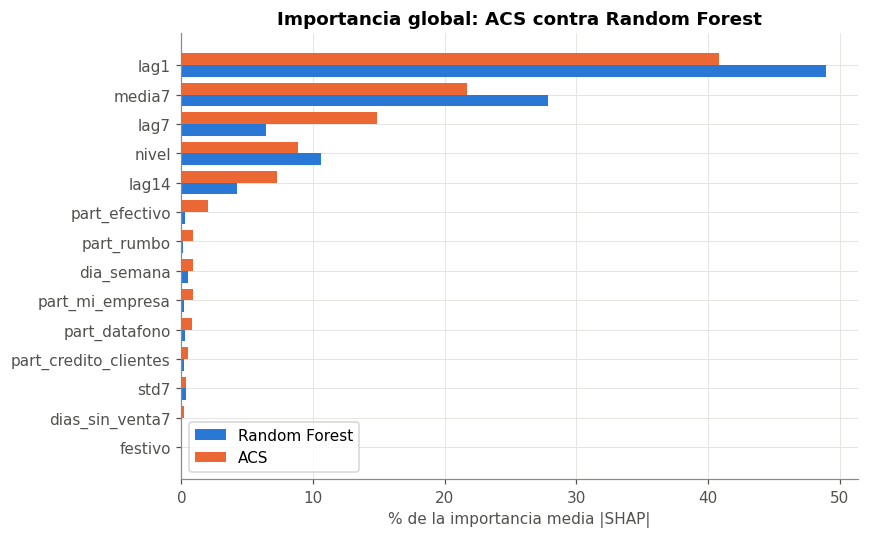

In [13]:
sh = pd.read_csv("../data/shap_global.csv")
comp = sh[sh["clave"].isin(["acs", "rf"])].pivot(index="variable", columns="clave", values="shap_abs")
comp = comp.div(comp.sum()) * 100
comp = comp.sort_values("acs", ascending=True)
fig, ax = plt.subplots(figsize=(8, 5))
yy = np.arange(len(comp))
ax.barh(yy - 0.2, comp["rf"], height=0.4, color=AZUL, label="Random Forest")
ax.barh(yy + 0.2, comp["acs"], height=0.4, color=NARANJA, label="ACS")
ax.set_yticks(yy); ax.set_yticklabels(comp.index); ax.set_xlabel("% de la importancia media |SHAP|"); ax.legend()
ax.set_title("Importancia global: ACS contra Random Forest")
plt.tight_layout()
comp.sort_values("acs", ascending=False).round(1).T

**Lectura.**

- **El orden de las variables es casi el mismo:** `lag1` y `media7` dominan en los dos modelos. El ACS no "inventa" señal; combina la de sus expertos.
- **La importancia del ACS está más repartida:** `lag7` pesa 14,8 % (contra 6,4 % en Random Forest), por el ingenuo estacional que usa en fin de semana. El mix de medios también pesa más (`part_efectivo` 2,0 % contra 0,3 %), porque decide en qué hoja cae cada fila.
- **Interpretable por construcción.** A diferencia de Random Forest, cada predicción del ACS se explica en dos niveles: **qué hoja** (reglas legibles sobre el tipo de negocio, el día y el tamaño) y **qué peso** tiene cada experto. El tablero muestra los dos.

## 19.11 Historia del diseño: cuatro versiones

El ciclo de desarrollo de la guía permite iterar sobre el diseño si el modelo no resulta superior, **reportando todo con honestidad**. El ACS pasó por cuatro versiones. Todas usan los mismos expertos, los mismos folds y el mismo presupuesto de búsqueda; cambian el solver y el entrenamiento del combinador.

| Versión | Cambio | Motivo |
|---|---|---|
| v1 | Momentos sin centrar $A = Z^\top Z/n$; raíz encogida con $\lambda = 10^{-6}$; pronósticos fuera de muestra en orden temporal; tope de 500 iteraciones | Diseño inicial |
| v2 | Matriz de errores $D = E^\top E / n$; tope de 5 000 iteraciones | El solver de v1 **no convergía** (100 % de los problemas en el tope): sus pesos se quedaban cerca del punto de partida (el promedio simple) |
| v3 | Raíz encogida hacia el promedio simple con la $\lambda$ buscada | Con el solver exacto el árbol sobreajusta; el "puzzle de la combinación" sugiere encoger hacia el promedio |
| v4 (final) | Pronósticos fuera de muestra por **ajuste cruzado** | Con ventana creciente los expertos ven menos días que los finales y el combinador subestima a los que más mejoran con datos |

```{warning}
**Advertencia de honestidad.** Las versiones 2 a 4 se diseñaron **después** de ver los resultados del bucle externo de las anteriores. Aunque cada cambio tiene una justificación teórica independiente, la estimación del bucle externo de la versión final es **algo optimista** (sesgo de selección del diseño). El test (3 – 23 sep) y los tres conjuntos de datos externos son las comprobaciones menos contaminadas.
```

In [14]:
versiones = {"v1": "modelo_original_v1_sin_converger.pkl", "v2": "modelo_original_v2_sin_encogimiento_raiz.pkl",
             "v3": "modelo_original_v3_encogimiento_raiz.pkl", "v4 (final)": "modelo_original.pkl"}
filas = []
y_tr = a_log(train["venta_total"].to_numpy())
for v, f in versiones.items():
    rv = pickle.load(open(DATA / "processed" / f, "rb"))
    pv = rv["pred_val"]
    e = y_tr[pv["fila"]] - pv["ACS"].to_numpy()
    rm = [np.sqrt(np.mean(e[pv["fold"] == k] ** 2)) for k in range(4)]
    ma = [np.mean(np.abs(e[pv["fold"] == k])) for k in range(4)]
    it = np.array(rv["final"].arbol_.iteraciones_)
    tope = rv["final"].arbol_.max_iter
    filas.append({"versión": v, "RMSE log bucle externo": f"{np.mean(rm):.4f} ± {np.std(rm, ddof=1):.4f}",
                  "MAE log bucle externo": f"{np.mean(ma):.4f} ± {np.std(ma, ddof=1):.4f}",
                  "RMSE log test": f"{np.sqrt(np.mean((a_log(test['venta_total']) - a_log(rv['pred_test'])) ** 2)):.4f}",
                  "% problemas en el tope de iteraciones": f"{(it >= tope).mean():.0%}",
                  "hojas (final)": rv["final"].arbol_.n_hojas()})
e = y_tr[pv["fila"]] - a_log(cargar("reg", "rf", "ninguno", "grid")["pred_val"].set_index("fila").loc[pv["fila"], "pred"].to_numpy())
filas.append({"versión": "Random Forest · Grid (referencia)",
              "RMSE log bucle externo": f"{np.mean([np.sqrt(np.mean(e[pv['fold'] == k] ** 2)) for k in range(4)]):.4f}",
              "MAE log bucle externo": f"{np.mean([np.mean(np.abs(e[pv['fold'] == k])) for k in range(4)]):.4f}",
              "RMSE log test": f"{cargar('reg', 'rf', 'ninguno', 'grid')['metricas_test']['rmse_log']:.4f}"})
pd.DataFrame(filas).set_index("versión").fillna("—")

,RMSE log bucle externo,MAE log bucle externo,RMSE log test,% problemas en el tope de iteraciones,hojas (final)
versión,,,,,
v1,0.8887 ± 0.1205,0.2832 ± 0.0485,0.6184,100%,3.00
v2,0.9102 ± 0.1148,0.2874 ± 0.0472,0.6209,0%,4.00
v3,0.9109 ± 0.1131,0.2888 ± 0.0446,0.6214,0%,4.00
v4 (final),0.8981 ± 0.1268,0.2878 ± 0.0511,0.6108,0%,4.00
Random Forest · Grid (referencia),0.8874,0.2906,0.6221,—,—


**Lectura de la historia del diseño.**

- **La v1 parecía la mejor** (0,8887, casi empatada con Random Forest, y la mejor en MAE). Pero su solver **no convergía en el 100 % de los problemas**, así que sus pesos eran prácticamente el punto de partida (el promedio simple, levemente movido). Su "ventaja" era una regularización accidental, no el mecanismo propuesto.
- **Con el solver correcto (v2 y v3) el árbol sobreajusta:** 0,910 y 0,911.
- **El ajuste cruzado (v4) recupera buena parte:** 0,898. Pero queda por debajo de Random Forest (0,887) en la validación externa, aunque mejor en test (0,611 contra 0,622).
- **Conclusión honesta:** ninguna versión supera a Random Forest en la validación externa. La lección metodológica es que **un error numérico produjo el mejor resultado aparente**. Sin la prueba de optimalidad (KKT) que se agregó después, se habría reportado una ventaja que no existía.